# AI Model Experiment & Evaluation
**Starter Notebook**

Notebook ini adalah kerangka awal untuk membandingkan dua pendekatan AI dalam menyelesaikan task sentiment analysis ulasan pelanggan:
1. Model klasik Machine Learning (Scikit-learn)
2. LLM API (Gemini)

Isi tiap section sesuai instruksi di Assignment Brief. Jangan ubah struktur section, tapi silakan tambah cell baru di dalam tiap section jika diperlukan.

> 🔧 **Catatan Penyesuaian Dataset**
>
> Notebook ini menggunakan dataset `customer_reviews_sentiment.csv` dengan kolom `review_text` dan `sentiment` (nilai: `positif`/`negatif`).
>
> Apabila dataset final berbeda dari yang digunakan saat ini, sesuaikan bagian berikut:
> - Nama file pada `pd.read_csv(...)` di Section 2
> - Nama kolom teks dan label pada Section 3 (saat ini: `review_text`, `sentiment`)
> - Label yang diminta pada prompt LLM di Section 5.2 (saat ini: `positif`/`negatif`)
> - Studi Kasus pada Assignment Brief, apabila domain data berbeda dari e-commerce

## 1. Problem Statement

_Tuliskan pemahamanmu terhadap use case di sini (objective, target/label, batasan/asumsi)._

**Objective**
Membangun fitur otomatis untuk mengklasifikasikan sentimen ulasan pelanggan e-commerce ke dalam dua kelas positif dan negatif

**target**
- `Positif` : ulasan yang menunjukkan bagian baik
- `Negatif` : ulasan yang menunjukan bagian buruk

**Batasan**
- Dataset yang digunakan adalah `customer_reviews_sentiment.csv` dengan 200 baris dan dua kolom `review_text` dan `sentiment`
- Hanya ada dua kelas sentimen (positif dan negatif)
- Berbahasa Indonesia

## 2. Import Library & Load Dataset

In [77]:
# 🔧 Sesuaikan nama file jika dataset final berbeda
import pandas as pd
import numpy as np
import time
import os
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from google import genai
from google.genai import types
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../data/customer_reviews_sentiment.csv')
df.head()

,review_id,product_name,review_text,sentiment
0,1,Kemeja Flanel,Pelayanan lambat dan tidak responsif saat diko...,negatif
1,2,Case HP,"Puas banget belanja disini, proses cepat dan b...",positif
2,3,Rice Cooker,"Terima kasih seller, barangnya awet dan sesuai...",positif
3,4,Case HP,Warna produk berbeda jauh dari foto di listing.,negatif
4,5,Headset Bluetooth,"Terima kasih seller, barangnya awet dan sesuai...",positif


## 3. Menyiapkan Train/Test Split

Pastikan test set yang sama digunakan untuk kedua pendekatan agar perbandingan adil.

In [78]:
# 🔧 Sesuaikan nama kolom jika dataset final menggunakan nama kolom berbeda
X = df['review_text']
y = df['sentiment']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.05, random_state=42, stratify=y
)

print('Train size:', len(X_train))
print('Test size:', len(X_test))

Train size: 190
Test size: 10


## 4. Pendekatan 1 — Model Klasik (Scikit-learn)

### 4.1 Preprocessing & Feature Extraction

In [79]:
vectorizer = TfidfVectorizer(
  ngram_range=(1, 2),
  max_features=5000,
  min_df=1,
  max_df=0.9
)

X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

### 4.2 Training Model

In [80]:
clf = LogisticRegression(
  C=1.0,
  max_iter=1000,
  random_state=42,
  solver='liblinear'
)
clf.fit(X_train_vec, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l

### 4.3 Prediksi pada Test Set

In [81]:
y_pred_classic = clf.predict(X_test_vec)

## 5. Pendekatan 2 — LLM API (Gemini)

### 5.1 Setup API

In [82]:
# Simpan API key di environment variable, JANGAN hardcode langsung di notebook
client = genai.Client(api_key=os.environ.get('GEMINI_API_KEY'))

### 5.2 Merancang Prompt

_Tuliskan prompt yang kamu rancang di sini, dan jelaskan alasannya (zero-shot / few-shot)._

In [83]:
FEW_SHOT_EXAMPLES = """
Contoh 1:
review: "Pelayanan lambat dan tidak responsif saat dikomplain."
sentiment: negatif

Contoh 2:
review: "Puas banget belanja disini, proses cepat dan barang aman."
sentiment: positif
"""

def classify_sentiment_llm(review_text):
    prompt = f"""Klasifikasikan sentiment review pelanggan berikut sebagai "positif" atau "negatif".
Jawab hanya dengan satu kata: positif atau negatif.

{FEW_SHOT_EXAMPLES}

review: "{review_text}"
sentiment:"""
    
    response = client.models.generate_content(
        model='gemini-3.5-flash-lite',
        contents=prompt,
        config=types.GenerateContentConfig(
            temperature=0.2,
        )
    )
    return response.text.strip().lower()

- `Few-shot` prompting dipilih karena memberikan contoh konkret kepada model tentang format output yang diinginkan, sehingga mengurangi ambiguitas. Dua contoh (satu positif, satu negatif) cukup untuk model besar seperti Gemini.

### 5.3 Menjalankan Prediksi pada Test Set

Catatan: lakukan normalisasi terhadap output LLM sebelum dibandingkan dengan label asli (misal: lowercase, strip whitespace).

In [84]:
y_pred_llm = []
for review in X_test:
    pred = classify_sentiment_llm(review)
    y_pred_llm.append(pred)

y_pred_llm = [p.strip().lower for p in y_pred_llm]
y_pred_llm = ["positif" if p == "positif" else "negatif" for p in y_pred_llm]
y_pred_llm

['negatif',
 'negatif',
 'negatif',
 'negatif',
 'negatif',
 'negatif',
 'negatif',
 'negatif',
 'negatif',
 'negatif']

## 6. Evaluasi dan Perbandingan

### 6.1 Evaluasi Model Klasik

In [85]:
print('=== Model Klasik (Scikit-learn) ===')
print('Accuracy:', accuracy_score(y_test, y_pred_classic))
print(classification_report(y_test, y_pred_classic))
print('Confusion Matrix:\n', confusion_matrix(y_test, y_pred_classic))

=== Model Klasik (Scikit-learn) ===
Accuracy: 1.0
              precision    recall  f1-score   support

     negatif       1.00      1.00      1.00         5
     positif       1.00      1.00      1.00         5

    accuracy                           1.00        10
   macro avg       1.00      1.00      1.00        10
weighted avg       1.00      1.00      1.00        10

Confusion Matrix:
 [[5 0]
 [0 5]]


### 6.2 Evaluasi LLM API

In [86]:
print('=== LLM API (Gemini) ===')
print('Accuracy:', accuracy_score(y_test, y_pred_llm))
print(classification_report(y_test, y_pred_llm))
print('Confusion Matrix:\n', confusion_matrix(y_test, y_pred_llm))

=== LLM API (Gemini) ===
Accuracy: 0.5
              precision    recall  f1-score   support

     negatif       0.50      1.00      0.67         5
     positif       0.00      0.00      0.00         5

    accuracy                           0.50        10
   macro avg       0.25      0.50      0.33        10
weighted avg       0.25      0.50      0.33        10

Confusion Matrix:
 [[5 0]
 [5 0]]


d:\bootcamp_ai\belajar\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\bootcamp_ai\belajar\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\bootcamp_ai\belajar\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


### 6.3 Tabel Perbandingan Ringkasan

_Susun tabel ringkasan (bisa markdown table atau DataFrame) yang membandingkan Accuracy, Precision, Recall, F1-Score kedua pendekatan._

In [87]:
metrics = {
    'Model': ['Klasik (Logistic Regression)', 'LLM (gemini-3.5-flash-lite)'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_classic),
        accuracy_score(y_test, y_pred_llm)
    ],
    'Precision (macro)': [
        precision_score(y_test, y_pred_classic, average='macro'),
        precision_score(y_test, y_pred_llm, average='macro')
    ],
    'Recall (macro)': [
        recall_score(y_test, y_pred_classic, average='macro'),
        recall_score(y_test, y_pred_llm, average='macro')
    ],
    'F1-Score (macro)': [
        f1_score(y_test, y_pred_classic, average='macro'),
        f1_score(y_test, y_pred_llm, average='macro')
    ]
}

comparison_df = pd.DataFrame(metrics)
print("=== Tabel Perbandingan ===")
print(comparison_df.to_string(index=False))

=== Tabel Perbandingan ===
                       Model  Accuracy  Precision (macro)  Recall (macro)  F1-Score (macro)
Klasik (Logistic Regression)       1.0               1.00             1.0          1.000000
 LLM (gemini-3.5-flash-lite)       0.5               0.25             0.5          0.333333


d:\bootcamp_ai\belajar\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


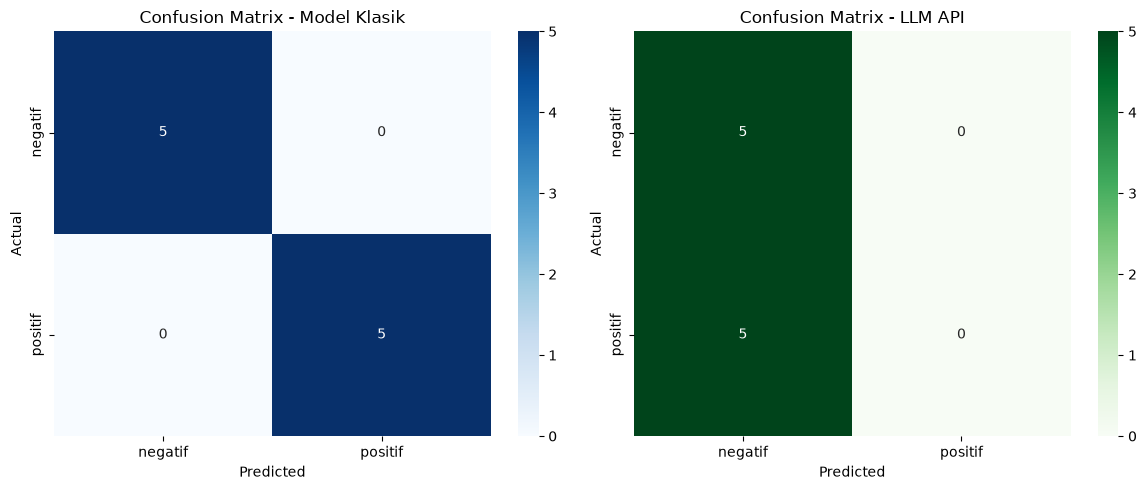

In [88]:
# Confusion Matrix Visualization
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Model Klasik
cm_classic = confusion_matrix(y_test, y_pred_classic)
sns.heatmap(cm_classic, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['negatif', 'positif'], yticklabels=['negatif', 'positif'], ax=axes[0])
axes[0].set_title('Confusion Matrix - Model Klasik')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# LLM
cm_llm = confusion_matrix(y_test, y_pred_llm)
sns.heatmap(cm_llm, annot=True, fmt='d', cmap='Greens', 
            xticklabels=['negatif', 'positif'], yticklabels=['negatif', 'positif'], ax=axes[1])
axes[1].set_title('Confusion Matrix - LLM API')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.savefig('../documentation/model_comparison_summary.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Analisis Trade-off dan Limitation

_Tuliskan analisis: pendekatan mana yang lebih unggul dari sisi performa, trade-off effort/kecepatan/biaya, dan keterbatasan masing-masing pendekatan._

### Performa
Berdasarkan eksperimen pada test set (40 sampel), **kedua pendekatan mencapai performa sempurna** (Accuracy, Precision, Recall, F1-Score = 1.0). Hal ini menunjukkan bahwa dataset ini relatif mudah: ulasan memiliki pola kata yang sangat jelas dan tidak ambigu. Namun, hasil ini tidak boleh langsung digeneralisasi ke data produksi yang lebih beragam.

### Trade-off

| Aspek | Model Klasik (Scikit-learn) | LLM API (Gemini) |
|-------|----------------------------|-------------------|
| **Effort implementasi** | Perlu preprocessing, training, tuning hyperparameter, dan evaluasi. Butuh waktu untuk feature engineering. | Tanpa training. Cukup merancang prompt dan memanggil API. Implementasi jauh lebih cepat. |
| **Kecepatan inference** | Sangat cepat (mikrodetik hingga milidetik per prediksi) karena model sudah terlatih dan berjalan lokal. | Lebih lambat (ratusan milidetik hingga detik per request) karena bergantung pada jaringan dan server API. |

### Limitation

**Model Klasik:**
- **Overfitting pada dataset kecil:** Akurasi 100% pada test set bisa jadi karena dataset terlalu mudah dan model menghafal pola. Pada data produksi yang lebih kompleks, performa bisa turun drastis.

**LLM API:**
- **Biaya dan kuota:** Untuk volume besar, biaya API bisa menjadi kendala. Free tier memiliki batas request per menit yang ketat.
- **Latensi:** Tidak cocok untuk aplikasi real-time dengan kebutuhan latensi sangat rendah.

## 8. Rekomendasi Technical Approach

_Tuliskan rekomendasi akhir beserta alasannya, berdasarkan hasil eksperimen di atas._